# 33. Bootstrap intervals for the decomposition of a ranking change (Proposition 3)

When the event definition changes from h₁ to h₂, I decompose the change in the standard AUC difference between two systems, D = (1 − π)Δpre + πΔin, exactly into three terms: reweighting, pre-onset discrimination and in-progress discrimination (Proposition 3, §3 of the manuscript). I report all three attributions (base h₁, Shapley–Shorrocks, base h₂), take the Shapley row as the convention, and give each term a 95% block-bootstrap percentile interval.

- Data: the price cache of the development period (Binance spot BTCUSDT one-minute data, 2023-01 to 2026-04) and the stored results of notebooks 16, 22 and 29.
- Pairs of definitions: 240 → 1440 minutes (main); 120 → 240, 240 → 480 and 480 → 1440 (secondary).
- Sections: (1) point estimates of π, Δpre, Δin and D for each window and the three attributions, where I check the closed form against an enumeration of all six orderings; (2) 7-day block bootstrap with the same draws for both definitions: intervals and sign-agreement shares; (3) block-length sensitivity (3, 7, 14, 30 days) and (4) leave-one-month-out for the Shapley terms of the main pair; (5) summary (`SHAPLEY_SUMMARY.json`).
- In every draw the three terms sum exactly to D₂ − D₁. I read the intervals as the sampling uncertainty of an algebraic attribution, not as causal effects.

I fix the reading rules in `33_SPEC.json`. This analysis is exploratory, and it leaves the preregistered confirmatory plan (H1, S, P1, P2) unchanged. I write the outputs to `shapley_decomposition_v1`.

In [1]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

# Shared with notebook 16 (identical code): VPIN, causal feature set, GBM settings.
REGIME_WINDOW_D = 30; RV_WINDOW = 1440; VPIN_BUCKETS_PER_DAY = 50; VPIN_WINDOW = 50; VPIN_LOOKBACK_D = 30
GBM_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                  class_weight='balanced', early_stopping=False, random_state=17)
FEATS = ['z_vol', 'tsr', 'z_hs', 'ret_5', 'ret_15', 'ret_60', 'ret_240', 'rv_15', 'rv_60', 'rv_240', 'rv_ratio_15_240',
         'dd_240', 'dd_1440', 'vol_intensity_15', 'sell_ratio_15', 'sell_ratio_60', 'vpin']

@njit(cache=False)
def _vpin_core(vol, buy, bucket, n_win):
    out = np.full(len(vol), np.nan); ring = np.zeros(n_win); k = 0; run = 0.0; cv = 0.0; cb = 0.0
    for i in range(len(vol)):
        v = vol[i]; b = buy[i]
        if not (v == v) or not (b == b) or v < 0:
            v = 0.0; b = 0.0
        cv += v; cb += min(max(b, 0.0), v)
        bs = bucket[i]
        if bs == bs and bs > 0 and cv >= bs:
            imb = abs(2.0 * cb - cv) / cv
            j = k % n_win; run += imb - ring[j]; ring[j] = imb; k += 1; cv = 0.0; cb = 0.0
        if k >= n_win:
            out[i] = run / n_win
    return out


def vpin_series(px):
    vol = px.volume.to_numpy(float); buy = px.taker_buy_vol.to_numpy(float)
    daily = px.volume.groupby(px.index.floor('D')).sum()
    size = (daily.rolling(VPIN_LOOKBACK_D, min_periods=VPIN_LOOKBACK_D).mean().shift(1) / VPIN_BUCKETS_PER_DAY)
    bucket = size.reindex(px.index.floor('D')).to_numpy(float)
    return _vpin_core(vol, buy, bucket, VPIN_WINDOW)


def causal_features(px, sg):
    c = px.close.astype(float); lc = np.log(c); r = lc.diff(); vol = px.volume.astype(float); sell = vol - px.taker_buy_vol.astype(float)
    F = pd.DataFrame(index=px.index)
    F['z_vol'] = sg.z_vol.astype(float); F['tsr'] = sg.tsr.astype(float); F['z_hs'] = sg.z_hs.astype(float)
    for k in (5, 15, 60, 240):
        F[f'ret_{k}'] = lc - lc.shift(k)
    for k in (15, 60, 240):
        F[f'rv_{k}'] = r.rolling(k, min_periods=k // 2).std()
    F['rv_ratio_15_240'] = F.rv_15 / F.rv_240
    F['dd_240'] = 1 - c / c.rolling(240, min_periods=120).max()
    F['dd_1440'] = 1 - c / c.rolling(1440, min_periods=720).max()
    F['vol_intensity_15'] = vol.rolling(15, min_periods=8).sum() / (vol.rolling(1440, min_periods=720).sum() / 96)
    F['sell_ratio_15'] = sell.rolling(15, min_periods=8).sum() / vol.rolling(15, min_periods=8).sum()
    F['sell_ratio_60'] = sell.rolling(60, min_periods=30).sum() / vol.rolling(60, min_periods=30).sum()
    F['vpin'] = vpin_series(px)
    return F.replace([np.inf, -np.inf], np.nan).astype('float32')
# Shared by notebooks 18 and 19: exact block-bootstrap AUC decomposition.
def week_pairs(sp, wp, sn, wn):
    """C[k, l] = over positives in block k, the number of negatives in block l with a lower score (+0.5 per tie).
    With block multiplicities w from the bootstrap, the AUC is w'Cw / ((w'P)(w'N)); w = 1 gives the ordinary AUC."""
    C = np.zeros((N_WEEKS, N_WEEKS))
    if len(sp) == 0 or len(sn) == 0:
        return C
    o = np.lexsort((sn, wn)); sn = sn[o]; wn = wn[o]
    bounds = np.searchsorted(wn, np.arange(N_WEEKS + 1), 'left')
    for l in range(N_WEEKS):
        a, b = bounds[l], bounds[l + 1]
        if a == b:
            continue
        seg = sn[a:b]; lo = np.searchsorted(seg, sp, 'left'); hi = np.searchsorted(seg, sp, 'right')
        C[:, l] = np.bincount(wp, weights=lo + 0.5 * (hi - lo), minlength=N_WEEKS)
    return C


def _ratio(a, b):
    return a / b if b > 0 else np.nan


STAT_KEYS = ['auc_standard', 'auc_pre', 'auc_in', 'share_in', 'diff_standard_minus_pre', 'in_share_of_excess', 'auc_calm',
             'auc_standard_within_regime', 'auc_pre_within_regime', 'auc_in_within_regime']


def make_parts(sm, code, calm, wk, dec):
    neg = code == 0; pre = code == 1; inn = code == 2; cnt = lambda k: np.bincount(wk[k], minlength=N_WEEKS).astype(float)
    P = dict(C_pre=week_pairs(sm[pre], wk[pre], sm[neg], wk[neg]), C_in=week_pairs(sm[inn], wk[inn], sm[neg], wk[neg]),
             C_calm=week_pairs(sm[(code > 0) & calm], wk[(code > 0) & calm], sm[neg & calm], wk[neg & calm]),
             P_pre=cnt(pre), P_in=cnt(inn), N=cnt(neg), P_calm=cnt((code > 0) & calm), N_calm=cnt(neg & calm),
             Cs_pre=np.zeros((N_WEEKS, N_WEEKS)), Cs_in=np.zeros((N_WEEKS, N_WEEKS)), Pq_pre=[], Pq_in=[], Nq=[])
    for q in range(10):
        kq = dec == q; nq = neg & kq; pq = pre & kq; iq = inn & kq
        P['Cs_pre'] += week_pairs(sm[pq], wk[pq], sm[nq], wk[nq]); P['Cs_in'] += week_pairs(sm[iq], wk[iq], sm[nq], wk[nq])
        P['Pq_pre'].append(cnt(pq)); P['Pq_in'].append(cnt(iq)); P['Nq'].append(cnt(nq))
    for k in ('Pq_pre', 'Pq_in', 'Nq'):
        P[k] = np.array(P[k])
    return P


def stats_from(P, w):
    q = lambda C: w @ C @ w
    Wn = w @ P['N']; Wp = w @ P['P_pre']; Wi = w @ P['P_in']; sp = q(P['C_pre']); si = q(P['C_in'])
    std = _ratio(sp + si, (Wp + Wi) * Wn); pre = _ratio(sp, Wp * Wn); inn = _ratio(si, Wi * Wn); pi = _ratio(Wi, Wp + Wi)
    nq = P['Nq'] @ w; pq = P['Pq_pre'] @ w; iq = P['Pq_in'] @ w; ssp = q(P['Cs_pre']); ssi = q(P['Cs_in'])
    return dict(auc_standard=std, auc_pre=pre, auc_in=inn, share_in=pi, diff_standard_minus_pre=std - pre,
                in_share_of_excess=_ratio(pi * (inn - 0.5), std - 0.5) if np.isfinite(inn) else 0.0,
                auc_calm=_ratio(q(P['C_calm']), (w @ P['P_calm']) * (w @ P['N_calm'])),
                auc_standard_within_regime=_ratio(ssp + ssi, ((pq + iq) * nq).sum()),
                auc_pre_within_regime=_ratio(ssp, (pq * nq).sum()), auc_in_within_regime=_ratio(ssi, (iq * nq).sum()))
import joblib
from itertools import permutations

OUT = SPOT_BASE / 'shapley_decomposition_v1'; OUT.mkdir(parents=True, exist_ok=True)
M16 = SPOT_BASE / 'methods_definitions_v1'
M22 = SPOT_BASE / 'peak_window_v1'
M29 = SPOT_BASE / 'ranking_vix_baseline_v1'
DNAME, DCL = '4pct', 0.04
H_LIST = [120, 240, 480, 1440]; H_REF = 240; H_24 = 1440
PAIRS = [(240, 1440), (120, 240), (240, 480), (480, 1440)]     # main pair first (the one in Section 3 of the manuscript)
PSCORES = ['M0_VF_logit', 'M1_vol_threshold', 'M3_GBM_rich', 'B0_RV24h_baseline']   # the common-minute set is the intersection over these (as in notebooks 29 and 32)
A_NAME, B_NAME = 'M3_GBM_rich', 'M0_VF_logit'                  # all differences are A - B (GBM - M0)
SEED = 20261101
N_BOOT = 2000; BLOCK_DAYS = 7                                  # section 2 (7-day blocks as in notebooks 22, 29, 32)
BLOCKS_SENS = [3, 7, 14, 30]; N_BOOT_SENS = 2000               # section 3
EVAL_LAST = ts(EVAL_END).value - (LEAD_MAX + 5) * NS
WINDOW_MIN = LEAD_MAX - LEAD_MIN + 1
ATTR = ['base_h1', 'shapley', 'base_h2']; TERMS = ['reweighting', 'pre_onset', 'in_progress']

for _p in [M16 / 'METHODS_FROZEN.json', M16 / 'METHODS_SPEC.json', M22 / '2_per_minute_by_window.csv', M29 / '1a_scores_by_window_common_minutes.csv']:
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 16, 22 and 29 are required: {_p}')
FROZEN16 = json.loads((M16 / 'METHODS_FROZEN.json').read_text()); SPEC16 = json.loads((M16 / 'METHODS_SPEC.json').read_text())
if sha256_file(M16 / 'METHODS_SPEC.json') != FROZEN16['spec_sha256'] or SPEC16['gbm_params'] != GBM_PARAMS or SPEC16['gbm_features'] != FEATS:
    raise RuntimeError('GUARD FAIL: notebook-16 spec/settings differ')

SPEC = {'title': 'Block-bootstrap intervals for the exact decomposition of a ranking change (Proposition 3); development sample; exploratory (Appendix B)',
        'inputs': 'spot cache, notebook-16 frozen models, notebook-22 per-minute point estimates (guard), notebook-29 common-minute scores (comparison); holdouts and the prospective folder not read',
        'quantity': 'D_h = AUC_std(A) - AUC_std(B) = (1 - pi_h) dpre_h + pi_h din_h on the common valid minutes; A = ' + A_NAME + ', B = ' + B_NAME,
        'decomposition': {'base_h1': 'D2 - D1 = (pi2 - pi1)(din1 - dpre1) + (1 - pi2)(dpre2 - dpre1) + pi2 (din2 - din1)',
                          'base_h2': 'D2 - D1 = (pi2 - pi1)(din2 - dpre2) + (1 - pi1)(dpre2 - dpre1) + pi1 (din2 - din1)',
                          'shapley': 'Shapley-Shorrocks attribution of the three factors (pi, dpre, din): average marginal contribution over the 6 orderings; equals the midpoint of the two base forms for this bilinear D',
                          'check': 'closed forms compared with explicit enumeration of the 6 orderings (tolerance 1e-12); the three terms must sum to D2 - D1 in every draw (tolerance 1e-12)'},
        'pairs': PAIRS, 'main_pair': PAIRS[0],
        'bootstrap': {'block_days': BLOCK_DAYS, 'draws': N_BOOT, 'same_draws_for_both_definitions': True, 'interval': '95% percentile'},
        'sensitivity': {'block_days': BLOCKS_SENS, 'draws': N_BOOT_SENS, 'leave_one_month_out': 'month blocks, dropped month weight 0'},
        'reading': 'a term is distinguishable from zero if its 95% interval excludes 0; the Shapley reweighting share (term / total change) is not read when the interval of the total change covers 0; '
                   'intervals quantify sampling uncertainty of an exact algebraic attribution on the development sample and are not causal effects; all three attributions are reported, Shapley as the convention',
        'seed': SEED, 'notebook16_spec_sha256': FROZEN16['spec_sha256'], 'holdouts': 'not used', 'status': 'exploratory; appendix B; no confirmatory plan changed'}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
_sp = OUT / '33_SPEC.json'
if _sp.exists() and _sp.read_bytes() != _raw:
    _sp.rename(OUT / f'33_SPEC.replaced_{pd.Timestamp.now(tz="UTC"):%Y%m%dT%H%M%S}.json')
_sp.write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest()
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16])

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/shapley_decomposition_v1 | spec sha256 235a92cec78e6007


## 0. Reproduction of scores and events by window (same code as section 0 of notebook 32)

In [2]:
t_ = time.time()
px, sg = load_btc_spot()
F = causal_features(px, sg)
T = px.index.asi8; close = px.close.to_numpy(float); volume = px.volume.to_numpy(float)
v_ = sg.z_vol.to_numpy(float); f_ = sg.tsr.to_numpy(float); h_ = sg.z_hs.to_numpy(float)
VALID = (np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0) & np.isfinite(v_) & np.isfinite(f_) & np.isfinite(h_) & (f_ >= 0) & (f_ <= 1))
EVM = VALID & (T >= ts(EVAL_START).value) & (T < EVAL_LAST)
DD240 = F.dd_240.to_numpy(float); CALM = np.isfinite(DD240) & (DD240 < DCL / 4)
_lc = np.log(np.where(np.isfinite(close) & (close > 0), close, np.nan))
RV = pd.Series(_lc).diff().rolling(RV_WINDOW, min_periods=RV_WINDOW // 2).std().to_numpy()
DEC = np.full(len(T), -1, np.int64); _okr = EVM & np.isfinite(RV)
DEC[_okr] = np.minimum((pd.Series(RV[_okr]).rank(pct=True).to_numpy() * 10).astype(int), 9)
WEEK = np.where(EVM, (T - ts(EVAL_START).value) // (BLOCK_DAYS * 1440 * NS), -1).astype(np.int64)
N_WEEKS = int(WEEK[EVM].max()) + 1
TCOLS = ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']


def catalog_H(H):
    E_ = price_only_catalog(close, volume, px.index, H=H, decline=DCL)
    for c_ in TCOLS:
        E_[c_] = pd.to_datetime(E_[c_], utc=True)
    return E_.sort_values('breach_utc').reset_index(drop=True)


def in_decline_mask(E_, y_):
    br = E_.breach_utc.astype('int64').to_numpy(); on = E_.onset_1pct_utc.astype('int64').to_numpy()
    pos = np.searchsorted(br, T + LEAD_MIN * NS, 'left'); ok = pos < len(br)
    inn = np.zeros(len(T), bool); inn[ok] = T[ok] >= on[pos[ok]]
    return inn & (y_ == 1)


E_ref = load_catalog(SPOT_BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv')
CAT = {H: catalog_H(H) for H in H_LIST}
if len(CAT[H_REF]) != len(E_ref) or any(not np.array_equal(CAT[H_REF][c_].astype('int64').to_numpy(), E_ref[c_].astype('int64').to_numpy()) for c_ in TCOLS):
    raise RuntimeError('GUARD FAIL: H=240 catalog differs from the notebook-2 catalog')
EV = {H: events_between(CAT[H], EVAL_START, EVAL_END).reset_index(drop=True) for H in H_LIST}
Xl = F[['z_vol', 'tsr']].to_numpy(float); okl = train_mask(T, VALID) & np.isfinite(Xl).all(axis=1)
cfg0 = FROZEN16['configs'][f'M0_VF_logit|{DNAME}']
m0 = new_logit().fit(Xl[okl], label_from_catalog(T, CAT[H_REF])[okl])
if not (np.allclose(m0[-1].coef_.ravel(), cfg0['coef'], rtol=1e-6, atol=1e-9) and np.isclose(m0[-1].intercept_[0], cfg0['intercept'], rtol=1e-6, atol=1e-9)):
    raise RuntimeError('GUARD FAIL: M0 refit differs from notebook 16')
cfg3 = FROZEN16['configs'][f'M3_GBM_rich|{DNAME}']; mp = SPOT_BASE / cfg3['model_file']
if sha256_file(mp) != cfg3['model_sha256']:
    raise RuntimeError('GUARD FAIL: notebook-16 GBM file SHA-256 differs')
g3 = joblib.load(mp)
IDX = np.flatnonzero(EVM); S = {}
s = np.full(len(T), np.nan); okp = EVM & np.isfinite(Xl).all(axis=1); s[okp] = m0.predict_proba(Xl[okp])[:, 1]; S['M0_VF_logit'] = s
S['M1_vol_threshold'] = np.where(VALID, F.z_vol.to_numpy(float), np.nan)
s = np.full(len(T), np.nan); s[IDX] = g3.predict_proba(F[FEATS].to_numpy(np.float32)[IDX])[:, 1]; S['M3_GBM_rich'] = s
S['B0_RV24h_baseline'] = np.where(VALID, RV, np.nan)
del Xl

PM22 = pd.read_csv(M22 / '2_per_minute_by_window.csv'); ONES = np.ones(N_WEEKS); LAB = {}
for H in H_LIST:
    yH = label_from_catalog(T, CAT[H]); innH = in_decline_mask(CAT[H], yH)
    LAB[H] = np.where(yH == 1, np.where(innH, 2, 1), 0).astype(np.int64)
    for sname in PSCORES:
        m = EVM & np.isfinite(S[sname]) & (DEC >= 0)
        pt = stats_from(make_parts(S[sname][m], LAB[H][m], CALM[m], WEEK[m], DEC[m]), ONES)
        ref = PM22[(PM22.H == H) & (PM22.score == sname)]
        if len(ref) != 1 or any(abs(pt[k] - float(ref.iloc[0][k])) > 1e-9 for k in ['auc_standard', 'auc_pre', 'auc_in', 'auc_pre_within_regime']):
            raise RuntimeError(f'GUARD FAIL: per-minute point estimate differs from notebook 22 (H={H}, {sname})')
MC = EVM & (DEC >= 0)
for sname in PSCORES:
    MC &= np.isfinite(S[sname])
print(f'PASS: notebook-16 scores verified; per-minute point estimates equal notebook 22 at every window ({time.time() - t_:.0f}s)')
print('events in the development period by window:', {H: len(EV[H]) for H in H_LIST}, '| common valid minutes:', int(MC.sum()))

PASS: notebook-16 scores verified; per-minute point estimates equal notebook 22 at every window (149s)
events in the development period by window: {120: 51, 240: 83, 480: 129, 1440: 218} | common valid minutes: 1750612


## 1. Point estimates and exact decomposition (closed form = enumeration of six orderings)

In [3]:
def decomp(p1, x1, y1, p2, x2, y2):
    """Three attributions of D2 - D1 with D = (1 - p) x + p y; x = dpre, y = din. Each value is (reweighting, pre_onset, in_progress). Works on arrays."""
    base1 = ((p2 - p1) * (y1 - x1), (1 - p2) * (x2 - x1), p2 * (y2 - y1))
    base2 = ((p2 - p1) * (y2 - x2), (1 - p1) * (x2 - x1), p1 * (y2 - y1))
    shap = ((p2 - p1) * ((y1 - x1) + (y2 - x2)) / 2, (x2 - x1) * ((1 - p1) + (1 - p2)) / 2, (y2 - y1) * (p1 + p2) / 2)
    return {'base_h1': base1, 'shapley': shap, 'base_h2': base2}


def shapley_enum(p1, x1, y1, p2, x2, y2):
    """Shapley value by explicit enumeration of the 6 orderings of the three factors (independent of the closed form)."""
    f = lambda p, x, y: (1 - p) * x + p * y
    lv = [(p1, p2), (x1, x2), (y1, y2)]; perms = list(permutations(range(3))); contrib = [0.0, 0.0, 0.0]
    for perm in perms:
        cur = [p1, x1, y1]; prev = f(*cur)
        for k in perm:
            cur[k] = lv[k][1]; now = f(*cur); contrib[k] = contrib[k] + (now - prev); prev = now
    return tuple(c / len(perms) for c in contrib)


PP = {H: {sn: make_parts(S[sn][MC], LAB[H][MC], CALM[MC], WEEK[MC], DEC[MC]) for sn in [A_NAME, B_NAME]} for H in H_LIST}


def quantities(w):
    """pi, dpre, din, D at every window definition under block weights w (A - B)."""
    q = {}
    for H in H_LIST:
        ra = stats_from(PP[H][A_NAME], w); rb = stats_from(PP[H][B_NAME], w)
        if np.isfinite(ra['share_in']) and np.isfinite(rb['share_in']) and abs(ra['share_in'] - rb['share_in']) > 1e-12:
            raise RuntimeError('GUARD FAIL: the two systems see different in-progress shares (they must share positives and negatives)')
        q[H] = dict(pi=ra['share_in'], dpre=ra['auc_pre'] - rb['auc_pre'], din=ra['auc_in'] - rb['auc_in'], D=ra['auc_standard'] - rb['auc_standard'],
                    a_std=ra['auc_standard'], b_std=rb['auc_standard'], a_pre=ra['auc_pre'], b_pre=rb['auc_pre'], a_in=ra['auc_in'], b_in=rb['auc_in'])
        ident = (1 - q[H]['pi']) * q[H]['dpre'] + q[H]['pi'] * q[H]['din']
        if np.isfinite(ident) and abs(ident - q[H]['D']) > 1e-10:
            raise RuntimeError(f'GUARD FAIL: identity (1 - pi) dpre + pi din != standard-AUC difference at H={H} ({ident:.12f} vs {q[H]["D"]:.12f})')
    return q


Q0 = quantities(ONES)
SC29 = pd.read_csv(M29 / '1a_scores_by_window_common_minutes.csv'); notes = []
for H in H_LIST:
    try:
        ga = SC29[(SC29.H == H) & (SC29.score == A_NAME)].iloc[0]; gb = SC29[(SC29.H == H) & (SC29.score == B_NAME)].iloc[0]
        d1 = abs((ga.auc_pre - gb.auc_pre) - Q0[H]['dpre']); d2 = abs((ga.auc_in - gb.auc_in) - Q0[H]['din'])
        notes.append(dict(H=H, abs_diff_dpre_vs_nb29=float(d1), abs_diff_din_vs_nb29=float(d2), same_minute_set=bool(max(d1, d2) < 1e-9)))
    except (IndexError, AttributeError):
        notes.append(dict(H=H, abs_diff_dpre_vs_nb29=np.nan, abs_diff_din_vs_nb29=np.nan, same_minute_set=False))
NB29 = pd.DataFrame(notes)
print('comparison with notebook 29 (1a, common minutes):'); print(NB29.to_string(index=False))
print('PASS: point estimates equal notebook 29' if NB29.same_minute_set.all() else 'Note: point estimates differ from notebook 29 by the amounts above (different minute set)')

rows = []
for h1, h2 in PAIRS:
    a, b = Q0[h1], Q0[h2]; dd = b['D'] - a['D']
    at = decomp(a['pi'], a['dpre'], a['din'], b['pi'], b['dpre'], b['din']); en = shapley_enum(a['pi'], a['dpre'], a['din'], b['pi'], b['dpre'], b['din'])
    if max(abs(en[k] - at['shapley'][k]) for k in range(3)) > 1e-12:
        raise RuntimeError('GUARD FAIL: Shapley closed form differs from the enumeration')
    for name in ATTR:
        if abs(sum(at[name]) - dd) > 1e-12:
            raise RuntimeError(f'GUARD FAIL: {name} terms do not sum to D2 - D1')
    row = dict(h1=h1, h2=h2, pi_h1=a['pi'], pi_h2=b['pi'], dpre_h1=a['dpre'], dpre_h2=b['dpre'], din_h1=a['din'], din_h2=b['din'], D_h1=a['D'], D_h2=b['D'], dD=dd)
    for name in ATTR:
        for k, term in enumerate(TERMS):
            row[f'{name}_{term}'] = at[name][k]
    row['shapley_reweighting_share'] = at['shapley'][0] / dd if abs(dd) > 1e-12 else np.nan
    rows.append(row)
PT = pd.DataFrame(rows); PT.to_csv(OUT / '1_decomposition_point.csv', index=False)
print('PASS: closed forms equal the enumeration; every attribution sums to D2 - D1')
print('\nper-window quantities (A - B = GBM - M0, common valid minutes):')
print(pd.DataFrame([dict(H=H, pi=Q0[H]['pi'], dpre=Q0[H]['dpre'], din=Q0[H]['din'], D=Q0[H]['D']) for H in H_LIST]).round(4).to_string(index=False))
print('\nmain pair 240 -> 1440: change in D = {:+.4f}'.format(PT.iloc[0].dD))
print(pd.DataFrame({name: [PT.iloc[0][f'{name}_{t}'] for t in TERMS] for name in ATTR}, index=TERMS).T.round(4))
display(PT.round(4))

comparison with notebook 29 (1a, common minutes):
   H  abs_diff_dpre_vs_nb29  abs_diff_din_vs_nb29  same_minute_set
 120                    0.0          1.110223e-16             True
 240                    0.0          0.000000e+00             True
 480                    0.0          0.000000e+00             True
1440                    0.0          0.000000e+00             True
PASS: point estimates equal notebook 29
PASS: closed forms equal the enumeration; every attribution sums to D2 - D1

per-window quantities (A - B = GBM - M0, common valid minutes):
   H     pi    dpre     din       D
 120 0.1402 -0.0166 -0.0043 -0.0149
 240 0.4137 -0.0189  0.0071 -0.0081
 480 0.7059 -0.0363  0.0478  0.0231
1440 0.9137 -0.0903  0.0707  0.0568

main pair 240 -> 1440: change in D = +0.0650
         reweighting  pre_onset  in_progress
base_h1       0.0130    -0.0062       0.0581
shapley       0.0467    -0.0240       0.0422
base_h2       0.0805    -0.0419       0.0263


,h1,h2,pi_h1,pi_h2,dpre_h1,dpre_h2,din_h1,din_h2,D_h1,D_h2,...,base_h1_reweighting,base_h1_pre_onset,base_h1_in_progress,shapley_reweighting,shapley_pre_onset,shapley_in_progress,base_h2_reweighting,base_h2_pre_onset,base_h2_in_progress,shapley_reweighting_share
0,240,1440,0.4137,0.9137,-0.0189,-0.0903,0.0071,0.0707,-0.0081,0.0568,...,0.0130,-0.0062,0.0581,0.0467,-0.0240,0.0422,0.0805,-0.0419,0.0263,0.7197
1,120,240,0.1402,0.4137,-0.0166,-0.0189,-0.0043,0.0071,-0.0149,-0.0081,...,0.0034,-0.0013,0.0047,0.0052,-0.0016,0.0031,0.0071,-0.0019,0.0016,0.7752
2,240,480,0.4137,0.7059,-0.0189,-0.0363,0.0071,0.0478,-0.0081,0.0231,...,0.0076,-0.0051,0.0287,0.0161,-0.0077,0.0228,0.0245,-0.0102,0.0168,0.5153
3,480,1440,0.7059,0.9137,-0.0363,-0.0903,0.0478,0.0707,0.0231,0.0568,...,0.0175,-0.0047,0.0210,0.0255,-0.0103,0.0186,0.0335,-0.0159,0.0162,0.7538


## 2. Block-bootstrap intervals (7-day blocks, same draws for both definitions)

  500/2000 draws (1s)
  1000/2000 draws (1s)
  1500/2000 draws (2s)
  2000/2000 draws (3s)

main pair 240 -> 1440 (2000 draws, 7-day blocks, 174 blocks; 3s)
   term   point      lo      hi  excludes_zero
  pi_h1  0.4137  0.3476  0.4719           True
  pi_h2  0.9137  0.8701  0.9491           True
dpre_h1 -0.0189 -0.0631  0.0216          False
dpre_h2 -0.0903 -0.1753 -0.0187           True
 din_h1  0.0071 -0.0178  0.0309          False
 din_h2  0.0707  0.0472  0.0934           True
   D_h1 -0.0081 -0.0402  0.0206          False
   D_h2  0.0568  0.0333  0.0801           True
     dD  0.0650  0.0394  0.0913           True

  base_h1:
       term   point      lo      hi  excludes_zero  share_draws_same_sign_as_point
reweighting  0.0130 -0.0055  0.0347          False                          0.9155
  pre_onset -0.0062 -0.0112 -0.0015           True                          0.9925
in_progress  0.0581  0.0323  0.0832           True                          1.0000

  shapley:
                 

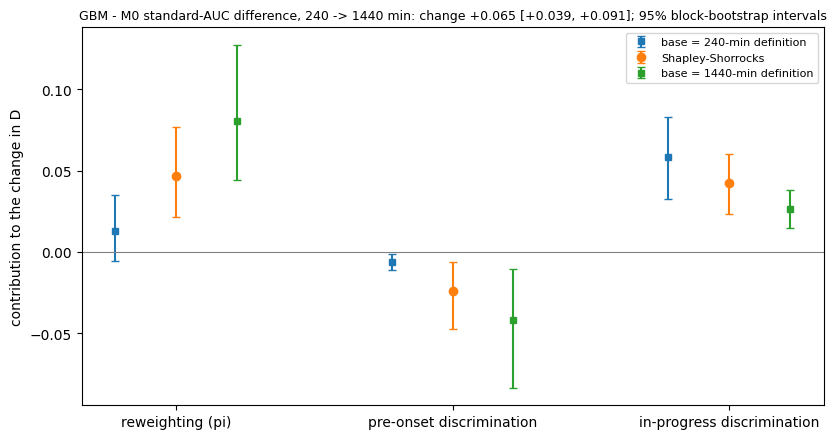

In [4]:
t_ = time.time(); rng = np.random.default_rng(SEED + 2)
W_BOOT = [np.bincount(rng.integers(0, N_WEEKS, N_WEEKS), minlength=N_WEEKS).astype(float) for _ in range(N_BOOT)]
QB = {H: {k: np.empty(N_BOOT) for k in ['pi', 'dpre', 'din', 'D']} for H in H_LIST}
for i, w in enumerate(W_BOOT):
    q = quantities(w)
    for H in H_LIST:
        for k in ['pi', 'dpre', 'din', 'D']:
            QB[H][k][i] = q[H][k]
    if (i + 1) % 500 == 0:
        print(f'  {i + 1}/{N_BOOT} draws ({time.time() - t_:.0f}s)', flush=True)


def interval(d):
    d = np.asarray(d, float); f = np.isfinite(d)
    lo, hi = (np.percentile(d[f], [2.5, 97.5]) if f.sum() else (np.nan, np.nan))
    return lo, hi, float(f.mean())


rows = []; draws_main = None
for h1, h2 in PAIRS:
    a, b = QB[h1], QB[h2]; dd = b['D'] - a['D']
    at = decomp(a['pi'], a['dpre'], a['din'], b['pi'], b['dpre'], b['din'])
    for name in ATTR:
        s_ = at[name][0] + at[name][1] + at[name][2]; f_ = np.isfinite(s_)
        if f_.any() and np.max(np.abs(s_[f_] - dd[f_])) > 1e-12:
            raise RuntimeError(f'GUARD FAIL: {name} terms do not sum to D2 - D1 in some draw')
    pt = PT[(PT.h1 == h1) & (PT.h2 == h2)].iloc[0]
    base = [('pi_h1', a['pi'], pt.pi_h1), ('pi_h2', b['pi'], pt.pi_h2), ('dpre_h1', a['dpre'], pt.dpre_h1), ('dpre_h2', b['dpre'], pt.dpre_h2),
            ('din_h1', a['din'], pt.din_h1), ('din_h2', b['din'], pt.din_h2), ('D_h1', a['D'], pt.D_h1), ('D_h2', b['D'], pt.D_h2), ('dD', dd, pt.dD)]
    for qname, d, p in base:
        lo, hi, fin = interval(d)
        rows.append(dict(h1=h1, h2=h2, attribution='-', term=qname, point=p, lo=lo, hi=hi, excludes_zero=bool(lo > 0 or hi < 0), share_draws_same_sign_as_point=float(np.nanmean(np.sign(d) == np.sign(p))), share_draws_finite=fin))
    dd_lo, dd_hi, _ = interval(dd)
    for name in ATTR:
        for k, term in enumerate(TERMS):
            d = at[name][k]; p = pt[f'{name}_{term}']; lo, hi, fin = interval(d)
            rows.append(dict(h1=h1, h2=h2, attribution=name, term=term, point=p, lo=lo, hi=hi, excludes_zero=bool(lo > 0 or hi < 0), share_draws_same_sign_as_point=float(np.nanmean(np.sign(d) == np.sign(p))), share_draws_finite=fin))
    sh = np.where(np.abs(dd) > 1e-12, at['shapley'][0] / dd, np.nan); lo, hi, fin = interval(sh)
    rows.append(dict(h1=h1, h2=h2, attribution='shapley', term='reweighting_share_of_dD', point=pt.shapley_reweighting_share, lo=lo, hi=hi,
                     excludes_zero=bool(lo > 0 or hi < 0), share_draws_same_sign_as_point=float(np.nanmean(np.sign(sh) == np.sign(pt.shapley_reweighting_share))), share_draws_finite=fin,
                     readable=bool(dd_lo > 0 or dd_hi < 0)))
    if (h1, h2) == PAIRS[0]:
        draws_main = pd.DataFrame(dict(draw=np.arange(N_BOOT), pi_h1=a['pi'], pi_h2=b['pi'], dpre_h1=a['dpre'], dpre_h2=b['dpre'], din_h1=a['din'], din_h2=b['din'], D_h1=a['D'], D_h2=b['D'], dD=dd,
                                       **{f'{name}_{term}': at[name][k] for name in ATTR for k, term in enumerate(TERMS)}))
BT = pd.DataFrame(rows); BT.to_csv(OUT / '2_decomposition_bootstrap.csv', index=False); draws_main.to_csv(OUT / '2b_draws_240_1440.csv', index=False)
main = BT[(BT.h1 == PAIRS[0][0]) & (BT.h2 == PAIRS[0][1])]
print(f'\nmain pair {PAIRS[0][0]} -> {PAIRS[0][1]} ({N_BOOT} draws, {BLOCK_DAYS}-day blocks, {N_WEEKS} blocks; {time.time() - t_:.0f}s)')
print(main[main.attribution == '-'][['term', 'point', 'lo', 'hi', 'excludes_zero']].round(4).to_string(index=False))
for name in ATTR:
    print(f'\n  {name}:'); print(main[main.attribution == name][['term', 'point', 'lo', 'hi', 'excludes_zero', 'share_draws_same_sign_as_point']].round(4).to_string(index=False))
# figure: three terms x three attributions for the main pair
fig, ax = plt.subplots(figsize=(8.5, 4.5)); x = np.arange(len(TERMS)); off = {'base_h1': -0.22, 'shapley': 0.0, 'base_h2': 0.22}; lab = {'base_h1': f'base = {PAIRS[0][0]}-min definition', 'shapley': 'Shapley-Shorrocks', 'base_h2': f'base = {PAIRS[0][1]}-min definition'}
for name in ATTR:
    sub = main[main.attribution == name].set_index('term').loc[TERMS]
    ax.errorbar(x + off[name], sub.point, yerr=[sub.point - sub.lo, sub.hi - sub.point], fmt='o' if name == 'shapley' else 's', capsize=3, label=lab[name], ms=6 if name == 'shapley' else 4)
ax.axhline(0, color='grey', lw=0.8); ax.set_xticks(x); ax.set_xticklabels(['reweighting (pi)', 'pre-onset discrimination', 'in-progress discrimination'])
dd_row = main[(main.attribution == '-') & (main.term == 'dD')].iloc[0]
ax.set_title(f'GBM - M0 standard-AUC difference, {PAIRS[0][0]} -> {PAIRS[0][1]} min: change {dd_row.point:+.3f} [{dd_row.lo:+.3f}, {dd_row.hi:+.3f}]; 95% block-bootstrap intervals', fontsize=9)
ax.set_ylabel('contribution to the change in D'); ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(OUT / '2_shapley_terms.png', dpi=140); plt.show()

## 3. Block-length sensitivity (Shapley terms of the main pair)

In [5]:
t_ = time.time(); rows = []; h1, h2 = PAIRS[0]


def block_ids(days):
    return np.where(EVM, (T - ts(EVAL_START).value) // (days * 1440 * NS), -1).astype(np.int64)


for days in BLOCKS_SENS:
    WK = block_ids(days); NW = int(WK[MC].max()) + 1
    globals()['N_WEEKS'] = NW                      # make_parts/stats_from read the module-level block count
    PPs = {H: {sn: make_parts(S[sn][MC], LAB[H][MC], CALM[MC], WK[MC], DEC[MC]) for sn in [A_NAME, B_NAME]} for H in (h1, h2)}
    rng = np.random.default_rng(SEED + 3 + days); arr = {H: {k: np.empty(N_BOOT_SENS) for k in ['pi', 'dpre', 'din', 'D']} for H in (h1, h2)}
    for i in range(N_BOOT_SENS):
        w = np.bincount(rng.integers(0, NW, NW), minlength=NW).astype(float)
        for H in (h1, h2):
            ra = stats_from(PPs[H][A_NAME], w); rb = stats_from(PPs[H][B_NAME], w)
            arr[H]['pi'][i] = ra['share_in']; arr[H]['dpre'][i] = ra['auc_pre'] - rb['auc_pre']; arr[H]['din'][i] = ra['auc_in'] - rb['auc_in']; arr[H]['D'][i] = ra['auc_standard'] - rb['auc_standard']
    a, b = arr[h1], arr[h2]; at = decomp(a['pi'], a['dpre'], a['din'], b['pi'], b['dpre'], b['din']); dd = b['D'] - a['D']
    pt = PT.iloc[0]
    lo, hi, _ = interval(dd); rows.append(dict(block_days=days, blocks=NW, draws=N_BOOT_SENS, attribution='-', term='dD', point=pt.dD, lo=lo, hi=hi, excludes_zero=bool(lo > 0 or hi < 0)))
    for k, term in enumerate(TERMS):
        lo, hi, _ = interval(at['shapley'][k]); rows.append(dict(block_days=days, blocks=NW, draws=N_BOOT_SENS, attribution='shapley', term=term, point=pt[f'shapley_{term}'], lo=lo, hi=hi, excludes_zero=bool(lo > 0 or hi < 0)))
    r_ = rows[-3:]
    print(f'block {days:2d} days ({NW} blocks): reweighting {r_[0]["point"]:+.4f} [{r_[0]["lo"]:+.4f}, {r_[0]["hi"]:+.4f}] | pre-onset {r_[1]["point"]:+.4f} [{r_[1]["lo"]:+.4f}, {r_[1]["hi"]:+.4f}] | in-progress {r_[2]["point"]:+.4f} [{r_[2]["lo"]:+.4f}, {r_[2]["hi"]:+.4f}] ({time.time() - t_:.0f}s)', flush=True)
globals()['N_WEEKS'] = int(WEEK[EVM].max()) + 1
BS = pd.DataFrame(rows); BS.to_csv(OUT / '3_block_sensitivity.csv', index=False); display(BS.round(4))

block  3 days (406 blocks): reweighting +0.0467 [+0.0187, +0.0754] | pre-onset -0.0240 [-0.0463, -0.0044] | in-progress +0.0422 [+0.0224, +0.0611] (35s)
block  7 days (174 blocks): reweighting +0.0467 [+0.0206, +0.0780] | pre-onset -0.0240 [-0.0459, -0.0043] | in-progress +0.0422 [+0.0233, +0.0605] (58s)
block 14 days (87 blocks): reweighting +0.0467 [+0.0217, +0.0759] | pre-onset -0.0240 [-0.0457, -0.0079] | in-progress +0.0422 [+0.0222, +0.0624] (76s)
block 30 days (41 blocks): reweighting +0.0467 [+0.0236, +0.0772] | pre-onset -0.0240 [-0.0406, -0.0090] | in-progress +0.0422 [+0.0225, +0.0639] (91s)


,block_days,blocks,draws,attribution,term,point,lo,hi,excludes_zero
0,3,406,2000,-,dD,0.0650,0.0360,0.0929,True
1,3,406,2000,shapley,reweighting,0.0467,0.0187,0.0754,True
2,3,406,2000,shapley,pre_onset,-0.0240,-0.0463,-0.0044,True
3,3,406,2000,shapley,in_progress,0.0422,0.0224,0.0611,True
4,7,174,2000,-,dD,0.0650,0.0394,0.0931,True
5,7,174,2000,shapley,reweighting,0.0467,0.0206,0.0780,True
6,7,174,2000,shapley,pre_onset,-0.0240,-0.0459,-0.0043,True
7,7,174,2000,shapley,in_progress,0.0422,0.0233,0.0605,True
8,14,87,2000,-,dD,0.0650,0.0394,0.0913,True
9,14,87,2000,shapley,reweighting,0.0467,0.0217,0.0759,True


## 4. Leave one month out (Shapley terms of the main pair, point estimates)

In [6]:
MONTH_ID = np.where(EVM, cal_fields(T)[1], -1).astype(np.int64)
months = np.unique(MONTH_ID[MC]); mid = np.searchsorted(months, MONTH_ID[MC]); globals()['N_WEEKS'] = len(months)
PPm = {H: {sn: make_parts(S[sn][MC], LAB[H][MC], CALM[MC], mid, DEC[MC]) for sn in [A_NAME, B_NAME]} for H in (h1, h2)}
lrows = []
for k, m_ in enumerate(months):
    w = np.ones(len(months)); w[k] = 0.0; q = {}
    for H in (h1, h2):
        ra = stats_from(PPm[H][A_NAME], w); rb = stats_from(PPm[H][B_NAME], w)
        q[H] = dict(pi=ra['share_in'], dpre=ra['auc_pre'] - rb['auc_pre'], din=ra['auc_in'] - rb['auc_in'], D=ra['auc_standard'] - rb['auc_standard'])
    at = decomp(q[h1]['pi'], q[h1]['dpre'], q[h1]['din'], q[h2]['pi'], q[h2]['dpre'], q[h2]['din'])
    lrows.append(dict(month_dropped=f'{(m_ - 1) // 12}-{(m_ - 1) % 12 + 1:02d}', dD=q[h2]['D'] - q[h1]['D'], **{f'shapley_{t}': at['shapley'][i] for i, t in enumerate(TERMS)}))
LO = pd.DataFrame(lrows); LO.to_csv(OUT / '4_leave_one_month_out.csv', index=False)
globals()['N_WEEKS'] = int(WEEK[EVM].max()) + 1
print('leave-one-month-out ranges (Shapley): reweighting [{:+.4f}, {:+.4f}], pre-onset [{:+.4f}, {:+.4f}], in-progress [{:+.4f}, {:+.4f}]; dD [{:+.4f}, {:+.4f}]'.format(
    LO.shapley_reweighting.min(), LO.shapley_reweighting.max(), LO.shapley_pre_onset.min(), LO.shapley_pre_onset.max(), LO.shapley_in_progress.min(), LO.shapley_in_progress.max(), LO.dD.min(), LO.dD.max()))
display(LO.round(4).head(12))

leave-one-month-out ranges (Shapley): reweighting [+0.0397, +0.0526], pre-onset [-0.0287, -0.0201], in-progress [+0.0369, +0.0463]; dD [+0.0568, +0.0710]


,month_dropped,dD,shapley_reweighting,shapley_pre_onset,shapley_in_progress
0,2023-01,0.0643,0.0456,-0.0236,0.0422
1,2023-02,0.0663,0.0459,-0.0240,0.0443
2,2023-03,0.0697,0.0490,-0.0228,0.0434
3,2023-04,0.0651,0.0447,-0.0233,0.0438
4,2023-05,0.0624,0.0480,-0.0263,0.0407
5,2023-06,0.0680,0.0457,-0.0229,0.0453
6,2023-07,0.0657,0.0473,-0.0237,0.0422
7,2023-08,0.0663,0.0478,-0.0240,0.0426
8,2023-09,0.0646,0.0477,-0.0240,0.0410
9,2023-10,0.0611,0.0397,-0.0201,0.0416


## 5. Summary

In [7]:
def reading(row):
    return 'distinguishable from zero' if row.excludes_zero else 'not distinguishable from zero'


sh = main[main.attribution == 'shapley'].set_index('term')
summary = dict(spec_sha256=SPEC_SHA, run_time=str(pd.Timestamp.now(tz='UTC').floor('s')), status=SPEC['status'], main_pair=PAIRS[0], draws=N_BOOT, block_days=BLOCK_DAYS, blocks=N_WEEKS,
               point=PT.iloc[0].to_dict(), bootstrap_main_pair=main.to_dict('records'),
               shapley_reading={t: reading(sh.loc[t]) for t in TERMS}, total_change_reading=reading(main[(main.attribution == '-') & (main.term == 'dD')].iloc[0]),
               reweighting_share=dict(point=float(sh.loc['reweighting_share_of_dD'].point), lo=float(sh.loc['reweighting_share_of_dD'].lo), hi=float(sh.loc['reweighting_share_of_dD'].hi), readable=bool(sh.loc['reweighting_share_of_dD'].readable)),
               all_pairs=BT.to_dict('records'), block_sensitivity=BS.to_dict('records'),
               leave_one_month_out_ranges={c: [float(LO[c].min()), float(LO[c].max())] for c in ['dD', 'shapley_reweighting', 'shapley_pre_onset', 'shapley_in_progress']},
               notebook29_comparison=NB29.to_dict('records'))
(OUT / 'SHAPLEY_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else (bool(o) if isinstance(o, np.bool_) else str(o))))
print('Shapley terms, main pair:', {t: f'{sh.loc[t].point:+.4f} [{sh.loc[t].lo:+.4f}, {sh.loc[t].hi:+.4f}] ({reading(sh.loc[t])})' for t in TERMS})
print('Done. Outputs in', OUT)

Shapley terms, main pair: {'reweighting': '+0.0467 [+0.0215, +0.0767] (distinguishable from zero)', 'pre_onset': '-0.0240 [-0.0472, -0.0059] (distinguishable from zero)', 'in_progress': '+0.0422 [+0.0234, +0.0602] (distinguishable from zero)'}
Done. Outputs in /content/drive/MyDrive/btc_lead_cost_results_77months_spot/shapley_decomposition_v1
